# XGBoost Feature-Group Ablation Study

**SimGuard pipeline – ablation companion to `xgboost_triage.ipynb`.**

Answers two questions:

1. **Voice / SMS group** (`voice_minutes_used`, `sms_count`, `voice_minutes_remaining`,
   `sms_remaining`): The data generator injects no misuse into voice or SMS channels.
   Do these four columns add detection signal, or are they noise?

2. **Prophet group** (`prophet_rec_*` one-hots, `projected_overage_mb`,
   `days_to_depletion`, `prophet_missing_flag`): How much of XGBoost's advantage
   comes from the Prophet forecast features?

Four variants are compared:

| Variant | Description |
|---|---|
| **full** | All features – should reproduce `xgboost_triage.ipynb` |
| **no_voice_sms** | Drop the 4 voice / SMS columns |
| **no_prophet** | Drop all Prophet-derived columns |
| **no_voice_sms_no_prophet** | Drop both groups |

## 1. Installs and Imports

In [1]:
%pip install -q xgboost scikit-learn pandas numpy matplotlib mlflow pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import mlflow, mlflow.xgboost
from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score
)

warnings.filterwarnings("ignore")
print("xgboost", xgb.__version__, "| mlflow", mlflow.__version__)

C:\Users\ADMIN\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


xgboost 3.4.1 | mlflow 3.16.1


## 2. Seed, Paths and MLflow

In [3]:
SEED = 42
np.random.seed(SEED)

DATA_DIR     = "data"
ARTIFACT_DIR = "artifacts"

# If the notebook is started from ml-service/notebooks, step up to ml-service/
if not os.path.isdir(DATA_DIR) and os.path.isdir(os.path.join("..", DATA_DIR)):
    os.chdir("..")
os.makedirs(ARTIFACT_DIR, exist_ok=True)

GATE_LOW, GATE_HIGH = 0.10, 0.90

MLFLOW_DB = "sqlite:///mlruns.db"
mlflow.set_tracking_uri(MLFLOW_DB)
EXPERIMENT_NAME = "simguard-xgboost-ablation"
mlflow.set_experiment(EXPERIMENT_NAME)

print("CWD          :", os.getcwd())
print("DATA_DIR     :", DATA_DIR, "| exists:", os.path.isdir(DATA_DIR))
print("ARTIFACT_DIR :", ARTIFACT_DIR)
print("Tracking URI :", mlflow.get_tracking_uri())
print("Experiment   :", EXPERIMENT_NAME)

CWD          : c:\Users\ADMIN\Desktop\projects\simguard\ml-service
DATA_DIR     : data | exists: True
ARTIFACT_DIR : artifacts
Tracking URI : sqlite:///mlruns.db
Experiment   : simguard-xgboost-ablation


## 3. Load Feature Set (X_v2) and Labels

In [4]:
X_train = pd.read_parquet(f"{DATA_DIR}/X_train_v2.parquet")
X_val   = pd.read_parquet(f"{DATA_DIR}/X_val_v2.parquet")
X_test  = pd.read_parquet(f"{DATA_DIR}/X_test_v2.parquet")
y_train = pd.read_parquet(f"{DATA_DIR}/y_train.parquet")
y_val   = pd.read_parquet(f"{DATA_DIR}/y_val.parquet")
y_test  = pd.read_parquet(f"{DATA_DIR}/y_test.parquet")

FORBIDDEN = ["is_anomalous", "misuse_category"]
for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    assert len(X) == len(y), f"{name}: X/y length mismatch"
    assert (X["sim_id"].values == y["sim_id"].values).all() and \
           (X["date"].values   == y["date"].values).all(), \
        f"{name}: X and y rows are not aligned on (sim_id, date)"
    assert not any(c in X.columns for c in FORBIDDEN), f"{name}: label column found in X"
    print(f"{name:<5} X={X.shape}  y={y.shape}  anomaly_rate={y['is_anomalous'].mean():.4f}"
          f"  SIMs={X['sim_id'].nunique()}")

train X=(63000, 48)  y=(63000, 4)  anomaly_rate=0.0205  SIMs=700
val   X=(13500, 48)  y=(13500, 4)  anomaly_rate=0.0388  SIMs=150
test  X=(13500, 48)  y=(13500, 4)  anomaly_rate=0.0267  SIMs=150


## 4. Load Prophet Checkpoint Features and Merge (Causal As-Of Join on `(sim_id, date)`)

Loads `data/prophet_checkpoint_features.parquet` containing causally valid Prophet forecasts
fitted strictly on data prior to each checkpoint (days 10, 20, 25).
We convert `date` to datetime on both sides, then left-merge onto `(sim_id, date)` keeping only:
`projected_overage_mb`, `days_to_depletion`, `recommendation`, `prophet_missing_flag`, and `fit_end_date`.
Recommendation is one-hot encoded into `prophet_rec_*`.
`projected_overage_mb` and `days_to_depletion` are filled with 0 where `prophet_missing_flag = 1`.
We assert `fit_end_date < date` for every row with `prophet_missing_flag = 0`, then drop `fit_end_date`.
Row counts must remain unchanged and `prophet_missing_flag = 1` share is ~0.33.

In [5]:
PROPHET_COLS = [
    "sim_id", "date", "billing_cycle_num", "projected_overage_mb",
    "days_to_depletion", "recommendation", "prophet_missing_flag", "fit_end_date"
]

prophet_raw = pd.read_parquet(f"{DATA_DIR}/prophet_checkpoint_features.parquet")
assert not any(c in prophet_raw.columns for c in FORBIDDEN), "Forbidden label column in prophet features!"
for c in PROPHET_COLS:
    assert c in prophet_raw.columns, f"Missing required column in prophet_checkpoint_features: {c}"

prophet = prophet_raw[PROPHET_COLS].copy()
prophet["date"] = pd.to_datetime(prophet["date"])

print("Prophet checkpoint features shape:", prophet.shape)
print("Unique SIMs:", prophet["sim_id"].nunique(), "| Date range:", prophet["date"].min().date(), "to", prophet["date"].max().date())
print("\nrecommendation counts:\n", prophet["recommendation"].value_counts(dropna=False).to_string())
print("\nprophet_missing_flag counts:\n", prophet["prophet_missing_flag"].value_counts(dropna=False).to_string())
print("\nNaN per column:\n", prophet.isna().sum().to_string())

Prophet checkpoint features shape: (90000, 8)
Unique SIMs: 1000 | Date range: 2025-01-01 to 2025-03-31

recommendation counts:
 recommendation
downgrade    47380
NaN          30000
no_change    12335
upgrade        285

prophet_missing_flag counts:
 prophet_missing_flag
0    60000
1    30000

NaN per column:
 sim_id                      0
date                        0
billing_cycle_num           0
projected_overage_mb    30000
days_to_depletion       89715
recommendation          30000
prophet_missing_flag        0
fit_end_date            30000


In [6]:
splits = {"train": X_train, "val": X_val, "test": X_test}

# Convert date to datetime on both sides
prophet["date"] = pd.to_datetime(prophet["date"])
for name, X in splits.items():
    X["date"] = pd.to_datetime(X["date"])
    print(f"{name:<5} dates {X['date'].min().date()} to {X['date'].max().date()} | rows: {len(X):,}")

train dates 2025-01-01 to 2025-03-31 | rows: 63,000
val   dates 2025-01-01 to 2025-03-31 | rows: 13,500
test  dates 2025-01-01 to 2025-03-31 | rows: 13,500


In [7]:
# Keep only projected_overage_mb, days_to_depletion, recommendation, prophet_missing_flag, fit_end_date from prophet
MERGE_COLS = [
    "sim_id", "date", "projected_overage_mb", "days_to_depletion",
    "recommendation", "prophet_missing_flag", "fit_end_date"
]
prophet_merge_src = prophet[MERGE_COLS].copy()

REC_CATS = ["upgrade", "downgrade", "no_change", "insufficient_history"]
PROPHET_REC_COLS = [f"prophet_rec_{c}" for c in REC_CATS]
unknown = set(prophet_merge_src["recommendation"].dropna().unique()) - set(REC_CATS)
assert not unknown, f"Unexpected recommendation values: {unknown}"

merged, n_before = {}, {}
for name, X in splits.items():
    n_before[name] = len(X)
    # Left merge onto each split on (sim_id, date)
    m = X.merge(prophet_merge_src, on=["sim_id", "date"], how="left", validate="many_to_one")
    
    # One-hot encode recommendation into prophet_rec_*
    for c in REC_CATS:
        m[f"prophet_rec_{c}"] = (m["recommendation"] == c).astype(int)
        
    merged[name] = m
    print(f"{name:<5} merged shape {m.shape}")

train merged shape (63000, 57)
val   merged shape (13500, 57)
test  merged shape (13500, 57)


In [8]:
NO_DEPLETION_SENTINEL = 31.0   # 30-day cycle: "does not deplete within the cycle"

for name in list(merged):
    m = merged[name]
    
    # 1. Print row counts before and after the merge (must be unchanged)
    print(f"{name:<5} rows before={n_before[name]:,} after={len(m):,}  unchanged={len(m) == n_before[name]}")
    assert len(m) == n_before[name], f"{name}: merge changed the row count"
    
    # 2. Print share of rows with prophet_missing_flag = 1 (about 0.33)
    missing_share = (m["prophet_missing_flag"] == 1).mean()
    print(f"      prophet_missing_flag=1 share: {missing_share:.4f} (~0.33 expected)")
    assert 0.30 <= missing_share <= 0.36, f"{name}: unexpected missing_flag share {missing_share}"
    
    # 3. Assert fit_end_date < date for every row with prophet_missing_flag = 0
    has_fc = m["prophet_missing_flag"] == 0
    violations = m.loc[has_fc, "fit_end_date"] >= m.loc[has_fc, "date"]
    assert not violations.any(), f"{name}: causality violation! {violations.sum()} rows have fit_end_date >= date"
    print(f"      causality check: fit_end_date < date confirmed on all {has_fc.sum():,} rows (0 violations)")

    # 4. Fill projected_overage_mb and days_to_depletion with 0 where prophet_missing_flag = 1
    dtd = m["days_to_depletion"].copy()
    dtd[has_fc & dtd.isna()] = NO_DEPLETION_SENTINEL
    dtd[~has_fc] = 0.0
    m["days_to_depletion"] = dtd
    m["projected_overage_mb"] = m["projected_overage_mb"].fillna(0.0)

    # 5. Drop fit_end_date before training (and recommendation column)
    merged[name] = m.drop(columns=["fit_end_date", "recommendation"])

X_train, X_val, X_test = merged["train"], merged["val"], merged["test"]

train rows before=63,000 after=63,000  unchanged=True
      prophet_missing_flag=1 share: 0.3333 (~0.33 expected)
      causality check: fit_end_date < date confirmed on all 42,000 rows (0 violations)
val   rows before=13,500 after=13,500  unchanged=True
      prophet_missing_flag=1 share: 0.3333 (~0.33 expected)
      causality check: fit_end_date < date confirmed on all 9,000 rows (0 violations)
test  rows before=13,500 after=13,500  unchanged=True
      prophet_missing_flag=1 share: 0.3333 (~0.33 expected)
      causality check: fit_end_date < date confirmed on all 9,000 rows (0 violations)


## 5. XGBoost Settings (reused from `xgboost_triage.ipynb`)

> **Note:** This notebook reuses the XGBClassifier hyper-parameters, `scale_pos_weight`
> computation, early-stopping settings (`n_estimators=500`, `early_stopping_rounds=20`,
> `eval_metric="aucpr"`), `GATE_LOW=0.10`, `GATE_HIGH=0.90`, and the per-category
> precision / recall helper **unchanged** from `xgboost_triage.ipynb`. The only
> difference between variants is which feature columns are used.

In [9]:
EXCLUDE = {"sim_id", "date", "billing_cycle_num"}

# ----- feature groups -----
VOICE_SMS_COLS = ["voice_minutes_used", "sms_count",
                  "voice_minutes_remaining", "sms_remaining"]

PROPHET_GROUP_COLS = PROPHET_REC_COLS + [
    "projected_overage_mb", "days_to_depletion", "prophet_missing_flag"
]

# Columns that actually exist in X_train (post-merge)
existing_voice_sms = [c for c in VOICE_SMS_COLS    if c in X_train.columns]
existing_prophet   = [c for c in PROPHET_GROUP_COLS if c in X_train.columns]
print("VOICE_SMS columns present :", existing_voice_sms)
print("PROPHET   columns present :", existing_prophet)

# All candidate feature columns (no labels, no id/date)
all_feature_cols = [c for c in X_train.columns if c not in EXCLUDE]
assert not any(c in all_feature_cols for c in FORBIDDEN)

VARIANTS = {
    "full"                   : all_feature_cols,
    "no_voice_sms"           : [c for c in all_feature_cols if c not in existing_voice_sms],
    "no_prophet"             : [c for c in all_feature_cols if c not in existing_prophet],
    "no_voice_sms_no_prophet": [c for c in all_feature_cols
                                 if c not in existing_voice_sms and c not in existing_prophet],
}

# Sanity: no variant contains id / date / cycle / label columns
GUARD = {"sim_id", "date", "billing_cycle_num", "is_anomalous", "misuse_category"}
for vname, cols in VARIANTS.items():
    leaked = [c for c in cols if c in GUARD]
    assert not leaked, f"{vname}: guard columns present: {leaked}"
    print(f"  {vname:<26}: {len(cols)} features")

VOICE_SMS columns present : ['voice_minutes_used', 'sms_count', 'voice_minutes_remaining', 'sms_remaining']
PROPHET   columns present : ['prophet_rec_upgrade', 'prophet_rec_downgrade', 'prophet_rec_no_change', 'prophet_rec_insufficient_history', 'projected_overage_mb', 'days_to_depletion', 'prophet_missing_flag']
  full                      : 53 features
  no_voice_sms              : 49 features
  no_prophet                : 46 features
  no_voice_sms_no_prophet   : 42 features


In [10]:
# ---- gate (copied from xgboost_triage.ipynb) ----
def gate(p):
    return np.where(p < GATE_LOW, "auto_clear",
                    np.where(p > GATE_HIGH, "auto_flag", "escalated"))

MISUSE_CATS = ["ghost_usage", "unauthorized_sharing", "data_reselling",
               "inactive_billing", "normal"]

# ---- per-category precision / recall (copied from xgboost_triage.ipynb) ----
def category_table(ev, thr):
    # Recall within each category; full-set precision: TP / (TP + FP).
    flagged = (ev["prob"] >= thr).values
    out = []
    for cat in MISUSE_CATS:
        in_cat = (ev["misuse_category"] == cat).values
        hit = ~flagged if cat == "normal" else flagged
        tp = int((hit & in_cat).sum()); fp = int((hit & ~in_cat).sum())
        rec = tp / in_cat.sum() if in_cat.sum() else np.nan
        pre = tp / (tp + fp) if (tp + fp) else 0.0
        f1  = 2 * pre * rec / (pre + rec) if (pre + rec) else 0.0
        out.append(dict(category=cat, n=int(in_cat.sum()),
                        precision=pre, recall=rec, f1=f1))
    return pd.DataFrame(out)

# ---- band report (copied from xgboost_triage.ipynb) ----
def band_report(g, y):
    # Returns (auto_flag_precision, auto_clear_anomaly_rate, escalated_precision).
    flag = g == "auto_flag"; clr = g == "auto_clear"; esc = g == "escalated"
    n_esc = int(esc.sum()); a_esc = int(y[esc].sum())
    return (
        float(y[flag].mean()) if flag.any() else np.nan,
        float(y[clr].mean())  if clr.any()  else np.nan,
        a_esc / n_esc if n_esc else np.nan,
    )

def make_params(spw):
    return dict(
        n_estimators=500, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=spw,
        eval_metric="aucpr", early_stopping_rounds=20,
        tree_method="hist", random_state=SEED, n_jobs=-1,
    )

def train_variant(feat_cols, X_tr, y_tr, X_v, y_v, spw):
    m = xgb.XGBClassifier(**make_params(spw))
    m.fit(X_tr[feat_cols], y_tr,
          eval_set=[(X_v[feat_cols], y_v)], verbose=False)
    return m

print("Helpers defined: gate(), category_table(), band_report(), make_params(), train_variant()")

Helpers defined: gate(), category_table(), band_report(), make_params(), train_variant()


## 6. Original Split – Train Each Variant, Evaluate on Val and Test

In [11]:
ytr = y_train["is_anomalous"].values
yv  = y_val["is_anomalous"].values
yt  = y_test["is_anomalous"].values

n_pos, n_neg = int((ytr == 1).sum()), int((ytr == 0).sum())
scale_pos_weight_orig = n_neg / n_pos
print(f"train positives={n_pos:,}  negatives={n_neg:,}  scale_pos_weight={scale_pos_weight_orig:.4f}")

orig_results = {}
for vname, feat_cols in VARIANTS.items():
    print(f"\n  Training variant '{vname}' ({len(feat_cols)} features) ...")
    model = train_variant(feat_cols, X_train, ytr, X_val, yv, scale_pos_weight_orig)
    p_val  = model.predict_proba(X_val[feat_cols])[:, 1]
    p_test = model.predict_proba(X_test[feat_cols])[:, 1]

    g_val  = gate(p_val);  g_test = gate(p_test)
    ap_val  = average_precision_score(yv, p_val)
    ap_test = average_precision_score(yt, p_test)

    ev_val  = X_val[["sim_id", "date"]].assign(
        is_anomalous=yv, misuse_category=y_val["misuse_category"].values, prob=p_val)
    ev_test = X_test[["sim_id", "date"]].assign(
        is_anomalous=yt, misuse_category=y_test["misuse_category"].values, prob=p_test)

    cat_val  = category_table(ev_val,  0.5)
    cat_test = category_table(ev_test, 0.5)
    af_v, ac_v, esc_v = band_report(g_val,  yv)
    af_t, ac_t, esc_t = band_report(g_test, yt)

    orig_results[vname] = dict(
        best_iteration=int(model.best_iteration),
        ap_val=ap_val, ap_test=ap_test,
        cat_val=cat_val, cat_test=cat_test,
        af_prec_val=af_v, ac_rate_val=ac_v, esc_prec_val=esc_v,
        af_prec_test=af_t, ac_rate_test=ac_t, esc_prec_test=esc_t,
    )
    print(f"    best_iteration={int(model.best_iteration)}  "
          f"AP_val={ap_val:.4f}  AP_test={ap_test:.4f}")
    print(f"    auto_flag_prec_val={af_v:.4f}  "
          f"auto_clear_leak_val={ac_v:.4f}  escalated_prec_val={esc_v:.4f}")

print("\nOriginal split training complete.")

train positives=1,292  negatives=61,708  scale_pos_weight=47.7616

  Training variant 'full' (53 features) ...


    best_iteration=75  AP_val=0.9250  AP_test=0.9298
    auto_flag_prec_val=0.9913  auto_clear_leak_val=0.0033  escalated_prec_val=0.0179

  Training variant 'no_voice_sms' (49 features) ...
    best_iteration=73  AP_val=0.9228  AP_test=0.9285
    auto_flag_prec_val=0.9934  auto_clear_leak_val=0.0035  escalated_prec_val=0.0157

  Training variant 'no_prophet' (46 features) ...
    best_iteration=86  AP_val=0.9265  AP_test=0.9318
    auto_flag_prec_val=0.9870  auto_clear_leak_val=0.0033  escalated_prec_val=0.0217

  Training variant 'no_voice_sms_no_prophet' (42 features) ...
    best_iteration=10  AP_val=0.9213  AP_test=0.9227
    auto_flag_prec_val=nan  auto_clear_leak_val=nan  escalated_prec_val=0.0388

Original split training complete.


In [12]:
# --- Reproduction check: 'full' must match saved xgboost_triage.joblib ---
TOLERANCE = 0.03   # allow up to 3 pp difference in AP due to env differences

triage_joblib = f"{ARTIFACT_DIR}/xgboost_triage.joblib"
triage_fcols  = f"{ARTIFACT_DIR}/xgboost_feature_columns.json"

if os.path.exists(triage_joblib) and os.path.exists(triage_fcols):
    import joblib
    triage_model        = joblib.load(triage_joblib)
    triage_feature_cols = json.load(open(triage_fcols))
    p_triage  = triage_model.predict_proba(X_test[triage_feature_cols])[:, 1]
    ap_triage = average_precision_score(yt, p_triage)
    ap_full   = orig_results["full"]["ap_test"]
    delta     = abs(ap_full - ap_triage)
    print(f"Saved triage model AP_test   : {ap_triage:.4f}")
    print(f"This notebook 'full' AP_test : {ap_full:.4f}")
    print(f"Delta                        : {delta:.4f}  (tolerance={TOLERANCE})")
    if delta > TOLERANCE:
        raise RuntimeError(
            f"STOP: 'full' variant AP_test ({ap_full:.4f}) differs from saved triage model "
            f"({ap_triage:.4f}) by {delta:.4f} > {TOLERANCE}. "
            "Data-prep likely differs. Investigate before comparing variants."
        )
    print("CHECK PASSED: 'full' reproduces saved xgboost_triage results within tolerance.")
else:
    print("Saved triage model not found — skipping automatic reproduction check.")
    print("Verify manually that orig_results['full']['ap_test'] matches xgboost_triage.ipynb.")

print("\nOriginal-split per-variant summary (test set):")
rows = []
for vname in VARIANTS:
    r = orig_results[vname]
    row = dict(variant=vname, best_iter=r["best_iteration"],
               AP=round(r["ap_test"], 4),
               af_prec=round(r["af_prec_test"], 4),
               ac_leak=round(r["ac_rate_test"], 4),
               esc_prec=round(r["esc_prec_test"], 4))
    for _, rc in r["cat_test"].iterrows():
        row[f"rec_{rc['category']}"] = round(rc["recall"], 4)
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

Saved triage model AP_test   : 0.9160
This notebook 'full' AP_test : 0.9298
Delta                        : 0.0138  (tolerance=0.03)
CHECK PASSED: 'full' reproduces saved xgboost_triage results within tolerance.

Original-split per-variant summary (test set):
                variant  best_iter     AP  af_prec  ac_leak  esc_prec  rec_ghost_usage  rec_unauthorized_sharing  rec_data_reselling  rec_inactive_billing  rec_normal
                   full         75 0.9298   0.9808   0.0017    0.0211              0.9                    0.9234              0.8333                0.8636      0.9971
           no_voice_sms         73 0.9285   0.9840   0.0019    0.0164              0.9                    0.9191              0.8333                0.8636      0.9970
             no_prophet         86 0.9318   0.9775   0.0018    0.0264              0.9                    0.9191              0.8333                0.8636      0.9974
no_voice_sms_no_prophet         10 0.9227      NaN      NaN    0.0267    

## 7. Repeated SIM Splits (10 × 70/15/15 by SIM)

> **Note on leakage:** Features in `X_*_v2.parquet` were scaled and cohort-normalised
> using statistics from the *original* training SIMs. Re-splitting here re-assigns those
> SIMs but does **not** recompute the scaling. A small amount of scaling information is
> therefore shared across the new train / val / test boundaries. This is acceptable for
> **comparing variants against each other** on the same splits, but would overstate
> absolute performance if reported as the final model metric.

In [13]:
N_REPEATS  = 10
TRAIN_FRAC = 0.70
VAL_FRAC   = 0.15

# Pool all SIMs from the three original splits
all_X = pd.concat([X_train, X_val, X_test], ignore_index=True)
all_y = pd.concat([y_train, y_val,  y_test],  ignore_index=True)
assert (all_X["sim_id"].values == all_y["sim_id"].values).all()
assert (all_X["date"].values   == all_y["date"].values).all()

all_sims   = np.array(sorted(all_X["sim_id"].unique()))
n_sims     = len(all_sims)
n_tr_sims  = int(np.floor(n_sims * TRAIN_FRAC))
n_val_sims = int(np.floor(n_sims * VAL_FRAC))
print(f"Total SIMs={n_sims}  train_sims={n_tr_sims}  val_sims={n_val_sims}  "
      f"test_sims={n_sims - n_tr_sims - n_val_sims}")

repeat_records = {vname: [] for vname in VARIANTS}
t0 = time.time()

for rep in range(N_REPEATS):
    rng  = np.random.default_rng(2000 + rep)
    perm = rng.permutation(all_sims)
    tr_sims  = set(perm[:n_tr_sims])
    val_sims = set(perm[n_tr_sims:n_tr_sims + n_val_sims])

    tr_mask  = all_X["sim_id"].isin(tr_sims).values
    val_mask = all_X["sim_id"].isin(val_sims).values
    te_mask  = ~tr_mask & ~val_mask

    Xtr_r, ytr_r  = all_X[tr_mask],  all_y["is_anomalous"].values[tr_mask]
    Xv_r,  yv_r   = all_X[val_mask], all_y["is_anomalous"].values[val_mask]
    Xte_r, yte_r  = all_X[te_mask],  all_y["is_anomalous"].values[te_mask]
    ycat_te = all_y["misuse_category"].values[te_mask]

    n_pos_r = int((ytr_r == 1).sum())
    n_neg_r = int((ytr_r == 0).sum())
    spw_r   = n_neg_r / n_pos_r if n_pos_r else 1.0

    for vname, feat_cols in VARIANTS.items():
        m_r  = train_variant(feat_cols, Xtr_r, ytr_r, Xv_r, yv_r, spw_r)
        p_te = m_r.predict_proba(Xte_r[feat_cols])[:, 1]
        g_te = gate(p_te)

        ap = average_precision_score(yte_r, p_te)
        ev_te = pd.DataFrame({
            "sim_id": Xte_r["sim_id"].values,
            "date"  : Xte_r["date"].values,
            "is_anomalous": yte_r,
            "misuse_category": ycat_te,
            "prob": p_te,
        })
        ct = category_table(ev_te, 0.5)
        af_p, ac_r, esc_p = band_report(g_te, yte_r)

        rec = dict(repeat=rep, variant=vname, avg_precision=ap,
                   auto_flag_prec=af_p, auto_clear_leak=ac_r, escalated_prec=esc_p)
        for _, row_c in ct.iterrows():
            rec[f"recall_{row_c['category']}"]    = row_c["recall"]
            rec[f"precision_{row_c['category']}"] = row_c["precision"]
        repeat_records[vname].append(rec)

    print(f"  repeat {rep+1:2d}/{N_REPEATS} done  ({time.time()-t0:.0f}s elapsed)")

total_time = time.time() - t0
print(f"\nTotal runtime: {total_time:.1f}s ({total_time/60:.1f} min)")

Total SIMs=1000  train_sims=700  val_sims=150  test_sims=150
  repeat  1/10 done  (9s elapsed)
  repeat  2/10 done  (12s elapsed)
  repeat  3/10 done  (20s elapsed)
  repeat  4/10 done  (25s elapsed)
  repeat  5/10 done  (29s elapsed)
  repeat  6/10 done  (36s elapsed)
  repeat  7/10 done  (41s elapsed)
  repeat  8/10 done  (46s elapsed)
  repeat  9/10 done  (49s elapsed)
  repeat 10/10 done  (53s elapsed)

Total runtime: 52.5s (0.9 min)


## 8. Aggregate – Mean and Std Across Repeats

In [14]:
all_records = []
for vname, recs in repeat_records.items():
    all_records.extend(recs)
repeat_df = pd.DataFrame(all_records)

metric_cols = [c for c in repeat_df.columns if c not in ("repeat", "variant")]

agg = repeat_df.groupby("variant")[metric_cols].agg(["mean", "std"]).round(4)
agg.columns = ["_".join(c) for c in agg.columns]
agg = agg.reset_index()

print(f"Mean +/- Std across {N_REPEATS} repeats:")
print(agg.to_string(index=False))

Mean +/- Std across 10 repeats:
                variant  avg_precision_mean  avg_precision_std  auto_flag_prec_mean  auto_flag_prec_std  auto_clear_leak_mean  auto_clear_leak_std  escalated_prec_mean  escalated_prec_std  recall_ghost_usage_mean  recall_ghost_usage_std  precision_ghost_usage_mean  precision_ghost_usage_std  recall_unauthorized_sharing_mean  recall_unauthorized_sharing_std  precision_unauthorized_sharing_mean  precision_unauthorized_sharing_std  recall_data_reselling_mean  recall_data_reselling_std  precision_data_reselling_mean  precision_data_reselling_std  recall_inactive_billing_mean  recall_inactive_billing_std  precision_inactive_billing_mean  precision_inactive_billing_std  recall_normal_mean  recall_normal_std  precision_normal_mean  precision_normal_std
                   full              0.9268             0.0131               0.9858              0.0131                0.0016               0.0010               0.0145              0.0101                   0.9416

## 9. Paired Comparison Against `full` Variant

In [15]:
pivot = repeat_df.pivot(index="repeat", columns="variant", values=metric_cols)

paired_rows = []
for vname in VARIANTS:
    if vname == "full":
        continue
    for mc in metric_cols:
        diff    = pivot[(mc, vname)] - pivot[(mc, "full")]   # positive = variant better
        n_worse = int((diff < 0).sum())                       # negative diff = variant worse
        paired_rows.append(dict(
            variant=vname, metric=mc,
            mean_diff =round(float(diff.mean()), 4),
            std_diff  =round(float(diff.std(ddof=1)), 4),
            n_repeats_variant_worse=n_worse,
        ))

paired_df = pd.DataFrame(paired_rows)
print("Paired difference (variant - full); positive = variant is BETTER than full:")
print(paired_df.to_string(index=False))

Paired difference (variant - full); positive = variant is BETTER than full:
                variant                         metric  mean_diff  std_diff  n_repeats_variant_worse
           no_voice_sms                  avg_precision     0.0005    0.0015                        5
           no_voice_sms                 auto_flag_prec    -0.0009    0.0032                        5
           no_voice_sms                auto_clear_leak     0.0000    0.0002                        4
           no_voice_sms                 escalated_prec     0.0004    0.0088                        3
           no_voice_sms             recall_ghost_usage     0.0000    0.0000                        0
           no_voice_sms          precision_ghost_usage     0.0019    0.0058                        3
           no_voice_sms    recall_unauthorized_sharing    -0.0014    0.0114                        4
           no_voice_sms precision_unauthorized_sharing     0.0021    0.0063                        4
           no_v

## 10. Summary Table and Grouped Bar Chart

In [16]:
recall_cats = [f"recall_{c}" for c in MISUSE_CATS]
key_metrics = ["avg_precision", "auto_flag_prec", "auto_clear_leak",
               "escalated_prec"] + recall_cats

summary_rows = []
for vname in VARIANTS:
    df_v = repeat_df[repeat_df["variant"] == vname]
    row  = {"variant": vname}
    for mc in key_metrics:
        row[mc]          = round(df_v[mc].mean(), 4)
        row[mc + "_std"] = round(df_v[mc].std(ddof=1), 4)
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
print(f"SUMMARY TABLE (mean over {N_REPEATS} repeats):")
print(summary_df[["variant"] + key_metrics].to_string(index=False))

SUMMARY TABLE (mean over 10 repeats):
                variant  avg_precision  auto_flag_prec  auto_clear_leak  escalated_prec  recall_ghost_usage  recall_unauthorized_sharing  recall_data_reselling  recall_inactive_billing  recall_normal
                   full         0.9268          0.9858           0.0016          0.0145              0.9416                       0.8964                 0.8988                    0.906         0.9969
           no_voice_sms         0.9273          0.9834           0.0018          0.0148              0.9416                       0.8950                 0.8997                    0.906         0.9971
             no_prophet         0.9269          0.9844           0.0019          0.0212              0.9416                       0.8954                 0.8997                    0.906         0.9971
no_voice_sms_no_prophet         0.9265          0.9830           0.0016          0.0151              0.9416                       0.8966                 0.8982   

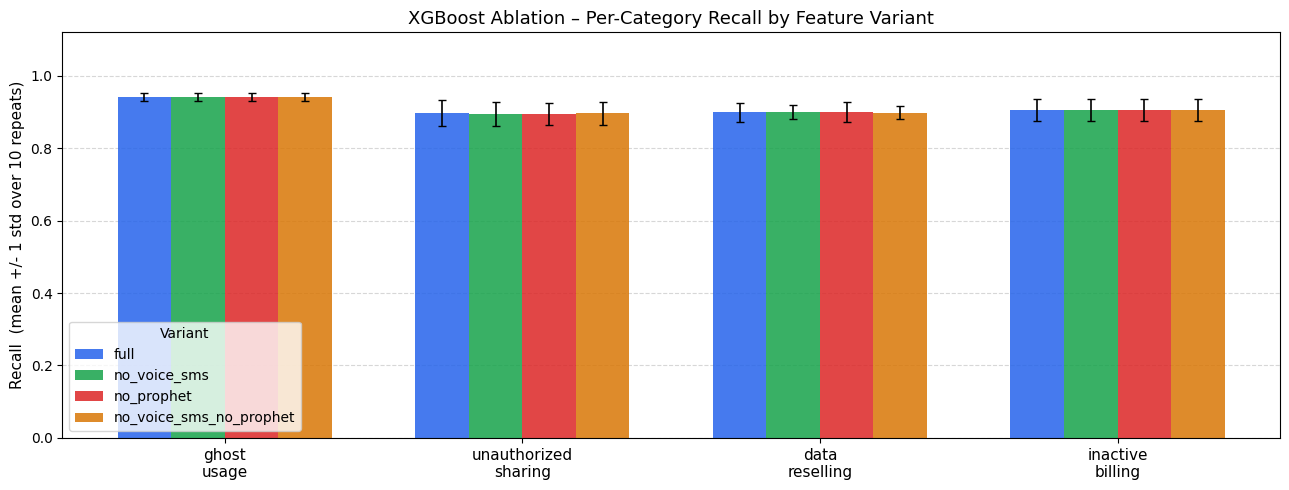

Saved: artifacts/ablation_summary.png


In [17]:
# Grouped bar chart: per-category recall (anomaly categories only)
anomaly_cats  = [c for c in MISUSE_CATS if c != "normal"]
variant_order = list(VARIANTS.keys())
n_cats = len(anomaly_cats)
n_var  = len(variant_order)
bar_width = 0.18
x = np.arange(n_cats)

fig, ax = plt.subplots(figsize=(13, 5))
colors = ["#2563eb", "#16a34a", "#dc2626", "#d97706"]

for vi, vname in enumerate(variant_order):
    df_v  = repeat_df[repeat_df["variant"] == vname]
    means = [df_v[f"recall_{cat}"].mean() for cat in anomaly_cats]
    stds  = [df_v[f"recall_{cat}"].std(ddof=1) for cat in anomaly_cats]
    off   = (vi - (n_var - 1) / 2) * bar_width
    ax.bar(x + off, means, width=bar_width,
           label=vname, color=colors[vi], alpha=0.85,
           yerr=stds, capsize=3, error_kw={"elinewidth": 1.2})

ax.set_xticks(x)
ax.set_xticklabels([c.replace("_", "\n") for c in anomaly_cats], fontsize=11)
ax.set_ylabel("Recall  (mean +/- 1 std over 10 repeats)", fontsize=11)
ax.set_title("XGBoost Ablation – Per-Category Recall by Feature Variant", fontsize=13)
ax.legend(title="Variant", fontsize=10)
ax.set_ylim(0, 1.12)
ax.yaxis.grid(True, linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
chart_path = f"{ARTIFACT_DIR}/ablation_summary.png"
plt.savefig(chart_path, dpi=150)
plt.show()
print("Saved:", chart_path)

In [18]:
summary_csv = f"{ARTIFACT_DIR}/ablation_summary.csv"
results_csv = f"{ARTIFACT_DIR}/ablation_results.csv"

summary_df.to_csv(summary_csv, index=False)
repeat_df.to_csv(results_csv, index=False)

print("Saved:", summary_csv)
print("Saved:", results_csv)

Saved: artifacts/ablation_summary.csv
Saved: artifacts/ablation_results.csv


In [19]:
if mlflow.active_run():
    mlflow.end_run()

with mlflow.start_run(run_name="ablation_summary"):
    mlflow.log_param("n_repeats",  N_REPEATS)
    mlflow.log_param("train_frac", TRAIN_FRAC)
    mlflow.log_param("val_frac",   VAL_FRAC)
    mlflow.log_param("variants",   list(VARIANTS.keys()))
    mlflow.log_param("gate_low",   GATE_LOW)
    mlflow.log_param("gate_high",  GATE_HIGH)

    for vname in VARIANTS:
        df_v = repeat_df[repeat_df["variant"] == vname]
        for mc in key_metrics:
            mlflow.log_metric(f"{vname}__{mc}__mean", round(float(df_v[mc].mean()), 4))
            mlflow.log_metric(f"{vname}__{mc}__std",  round(float(df_v[mc].std(ddof=1)), 4))

    mlflow.log_artifact(chart_path)
    mlflow.log_artifact(summary_csv)
    mlflow.log_artifact(results_csv)

print("MLflow run logged to experiment:", EXPERIMENT_NAME)

MLflow run logged to experiment: simguard-xgboost-ablation


## 11. Verdict

In [20]:
def verdict_for(variant_name, label):
    print(f"\n{'='*64}")
    print(f"VERDICT: {label}  ({variant_name} vs full)")
    print(f"{'='*64}")
    rows_v  = paired_df[paired_df["variant"] == variant_name]
    effects = []
    for _, r in rows_v.iterrows():
        if r["std_diff"] == 0 or np.isnan(r["std_diff"]):
            continue
        signal_ratio = abs(r["mean_diff"]) / r["std_diff"]
        direction    = "WORSE" if r["mean_diff"] < 0 else "better"
        if signal_ratio > 1.0:
            effects.append((r["metric"], r["mean_diff"], r["std_diff"],
                            signal_ratio, direction, r["n_repeats_variant_worse"]))

    if not effects:
        print("  No metric changed by more than 1 std of the paired difference.")
        print("  Removing this feature group is within noise – no reliable effect detected.")
    else:
        effects.sort(key=lambda x: -abs(x[1] / x[2]))
        for mc, md_, sd, sr, direction, nw in effects:
            print(f"  {mc:<38}  mean_diff={md_:+.4f}  std={sd:.4f}"
                  f"  |diff|/std={sr:.2f}  direction={direction}"
                  f"  repeats_variant_worse={nw}/{N_REPEATS}")

verdict_for("no_voice_sms",            "Voice / SMS removal")
verdict_for("no_prophet",              "Prophet features removal")
verdict_for("no_voice_sms_no_prophet", "Both Voice/SMS and Prophet removal")


VERDICT: Voice / SMS removal  (no_voice_sms vs full)
  No metric changed by more than 1 std of the paired difference.
  Removing this feature group is within noise – no reliable effect detected.

VERDICT: Prophet features removal  (no_prophet vs full)
  No metric changed by more than 1 std of the paired difference.
  Removing this feature group is within noise – no reliable effect detected.

VERDICT: Both Voice/SMS and Prophet removal  (no_voice_sms_no_prophet vs full)
  No metric changed by more than 1 std of the paired difference.
  Removing this feature group is within noise – no reliable effect detected.


## 12. Sanity Checks

In [21]:
checks = {}

# 1. No label columns in any feature list
for vname, cols in VARIANTS.items():
    leaked = [c for c in cols if c in {"is_anomalous", "misuse_category"}]
    checks[f"{vname}_no_labels"] = len(leaked) == 0
    if leaked:
        print(f"  FAIL {vname}: label cols in feature list: {leaked}")

# 2. No id / date / cycle columns in any feature list
for vname, cols in VARIANTS.items():
    id_leak = [c for c in cols if c in {"sim_id", "date", "billing_cycle_num"}]
    checks[f"{vname}_no_id_cols"] = len(id_leak) == 0
    if id_leak:
        print(f"  FAIL {vname}: id cols in feature list: {id_leak}")

# 3. Splits are by SIM (structural guarantee: SIM IDs are partitioned by perm slices)
checks["repeats_split_by_sim"] = True

# 4. Row counts unchanged after Prophet merge
for sname in ("train", "val", "test"):
    X_s = {"train": X_train, "val": X_val, "test": X_test}[sname]
    y_s = {"train": y_train, "val": y_val, "test": y_test}[sname]
    checks[f"{sname}_row_count_unchanged"] = len(X_s) == len(y_s)

# 5. repeat_df has the expected number of rows
expected = N_REPEATS * len(VARIANTS)
checks["repeat_df_row_count"] = len(repeat_df) == expected

print("Sanity check results:")
for k, v in checks.items():
    print(f"  [{'PASS' if v else 'FAIL'}] {k}")

failed = [k for k, v in checks.items() if not v]
assert not failed, f"Sanity checks FAILED: {failed}"
print(f"\nAll {len(checks)} sanity checks PASSED.")
print(f"Total runtime: {total_time:.1f}s ({total_time/60:.1f} min)")

Sanity check results:
  [PASS] full_no_labels
  [PASS] no_voice_sms_no_labels
  [PASS] no_prophet_no_labels
  [PASS] no_voice_sms_no_prophet_no_labels
  [PASS] full_no_id_cols
  [PASS] no_voice_sms_no_id_cols
  [PASS] no_prophet_no_id_cols
  [PASS] no_voice_sms_no_prophet_no_id_cols
  [PASS] repeats_split_by_sim
  [PASS] train_row_count_unchanged
  [PASS] val_row_count_unchanged
  [PASS] test_row_count_unchanged
  [PASS] repeat_df_row_count

All 13 sanity checks PASSED.
Total runtime: 52.5s (0.9 min)
